## Lab Task 1: Dataset Loading and Visualization

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "jamaltariqcheema/pima-indians-diabetes-dataset",
  "diabetes.csv"
)

print("Dataset loaded successfully:")
display(df.head())

Using Colab cache for faster access to the 'pima-indians-diabetes-dataset' dataset.
Dataset loaded successfully:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


### Data Inspection

In [17]:
df.shape

(768, 9)

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 54.1 KB


In [19]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


### Target Variable Distribution Visualization

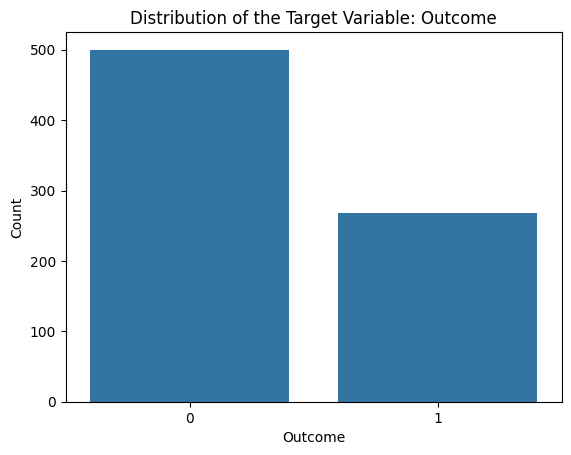

In [20]:
target_column = 'Outcome'

sns.countplot(x=target_column, data=df)
plt.title(f'Distribution of the Target Variable: {target_column}')
plt.xlabel(target_column)
plt.ylabel('Count')
plt.show()

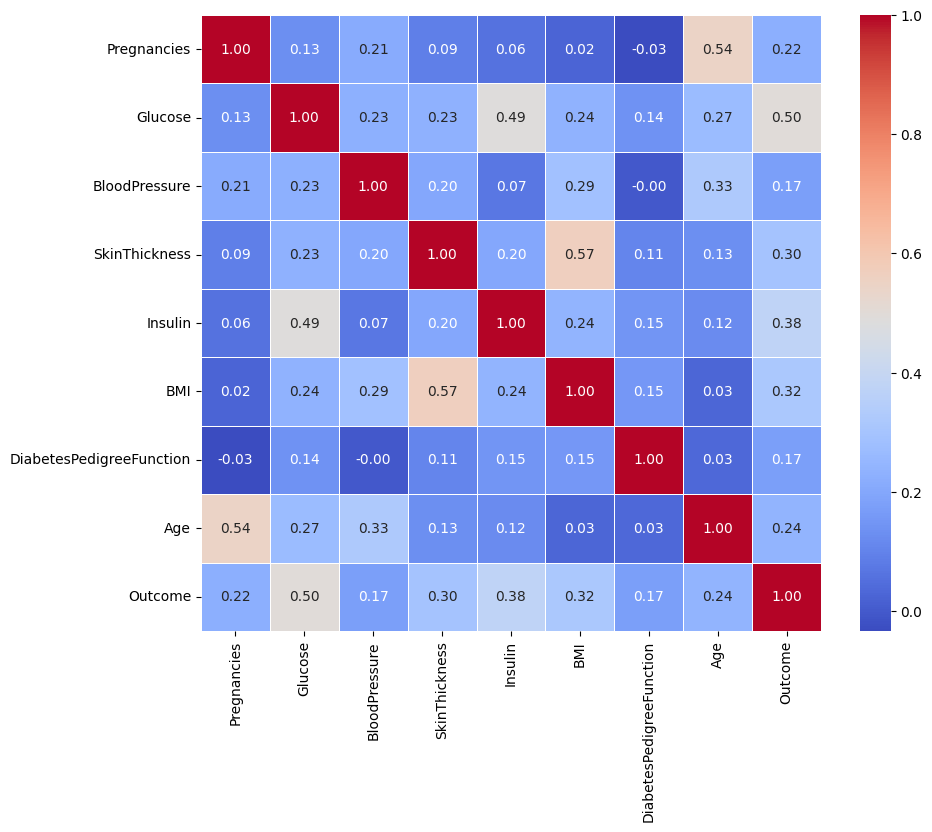

In [27]:
corr_matrix = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.show()

### Split Data into Training and Testing Sets

In [28]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Outcome'])
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (614, 8)
X_test shape: (154, 8)
y_train shape: (614,)
y_test shape: (154,)


## Lab Task 2: Basic Perceptron Implementation

In [31]:
class PerceptronFromScratch:
    def __init__(self, learning_rate=0.01, epochs=100):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        # Train the perceptron
        for epoch in range(self.epochs):
            for idx, x_i in enumerate(X):
                # Calculate the linear combination
                linear_output = np.dot(x_i, self.weights) + self.bias
                # Activation function (Heaviside step function: 1 if >= 0 else 0)
                y_predicted = 1 if linear_output >= 0 else 0

                # Weight and bias update rule
                update = self.lr * (y[idx] - y_predicted)
                self.weights += update * x_i
                self.bias += update

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return np.where(linear_output >= 0, 1, 0)

In [35]:
X_train_arr = X_train.to_numpy()
y_train_arr = y_train.to_numpy()
X_test_arr = X_test.to_numpy()
y_test_arr = y_test.to_numpy()

perceptron = PerceptronFromScratch(learning_rate=0.01, epochs=100)
perceptron.fit(X_train_arr, y_train_arr)

In [36]:
y_pred = perceptron.predict(X_test_arr)

In [37]:
accuracy = np.mean(y_pred == y_test_arr) * 100
print(f"Trained Perceptron Weights: {perceptron.weights}")
print(f"Trained Perceptron Bias: {perceptron.bias}")
print(f"Classification Accuracy on Test Set: {accuracy:.2f}%")

Trained Perceptron Weights: [  7.61     -0.8     -10.105     1.11      1.72      3.095     2.41506
  -2.09   ]
Trained Perceptron Bias: -15.449999999999715
Classification Accuracy on Test Set: 62.99%


## Lab Task 3: Perceptron Learning Curve and Weight Visualization

In [42]:
class PerceptronWithTracking:
    def __init__(self, learning_rate=0.01, epochs=100):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.errors_log = [] # To record number of misclassifications per epoch

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.errors_log = []

        for epoch in range(self.epochs):
            errors = 0
            for idx, x_i in enumerate(X):
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_predicted = 1 if linear_output >= 0 else 0

                # Compute update
                update = self.lr * (y[idx] - y_predicted)

                # If update is not zero, we had a misclassification
                if update != 0:
                    self.weights += update * x_i
                    self.bias += update
                    errors += 1

            self.errors_log.append(errors)

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return np.where(linear_output >= 0, 1, 0)

In [43]:
model = PerceptronWithTracking(learning_rate=0.01, epochs=100)
model.fit(X_train_arr, y_train_arr)

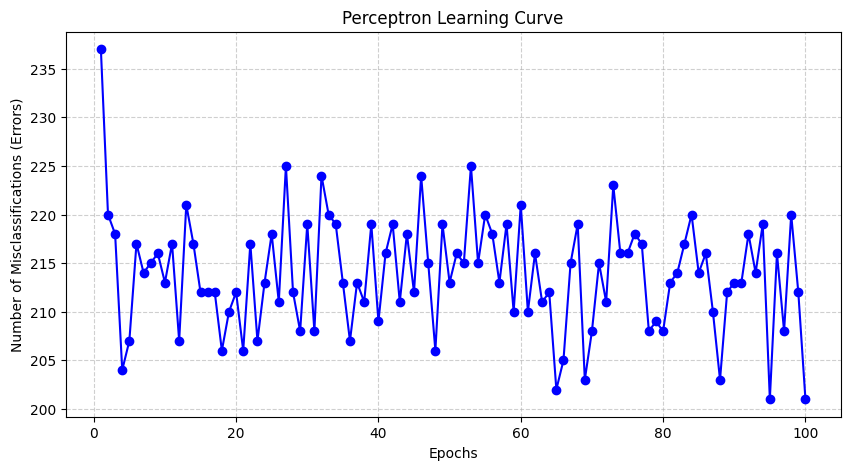

In [46]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(model.errors_log) + 1), model.errors_log, marker='o', color='b')
plt.title('Perceptron Learning Curve')
plt.xlabel('Epochs')
plt.ylabel('Number of Misclassifications (Errors)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [47]:
print(f"Final Bias: {model.bias:.4f}\n")

Final Bias: -15.4500



/tmp/ipykernel_2334/1027530750.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=model.weights, y=feature_names, palette='viridis')


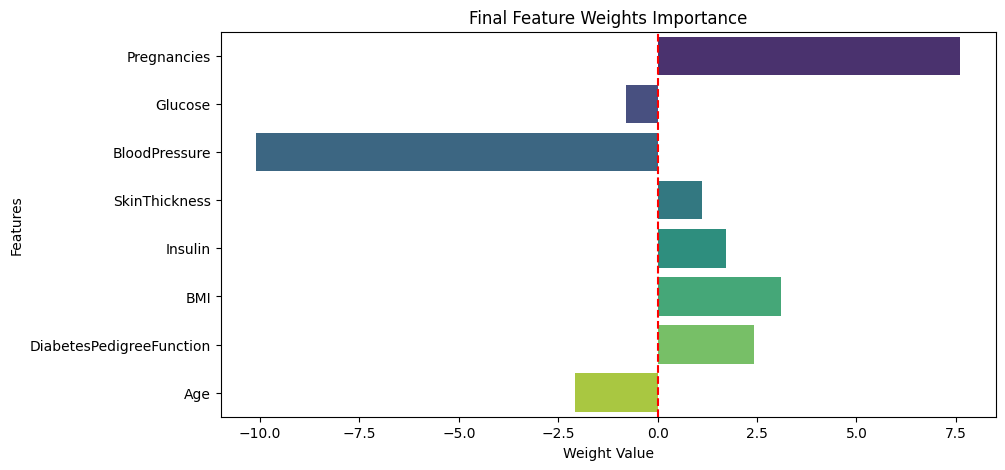

In [52]:
feature_names = X_train.columns
plt.figure(figsize=(10, 5))
sns.barplot(x=model.weights, y=feature_names, palette='viridis')
plt.title('Final Feature Weights Importance')
plt.xlabel('Weight Value')
plt.ylabel('Features')
plt.axvline(0, color='red', linestyle='--')
plt.show()

### 2D Decision Boundary Visualization
Since our dataset has 8 dimensions, we cannot visualize the decision boundary in 8D. Instead, we can train a separate 2D Perceptron using the two most correlated features (**Glucose** and **BMI**) to easily plot and inspect the linear decision boundary.

In [53]:
X_train_2d = X_train[['Glucose', 'BMI']].to_numpy()
X_test_2d = X_test[['Glucose', 'BMI']].to_numpy()

In [54]:
model_2d = PerceptronWithTracking(learning_rate=0.01, epochs=100)
model_2d.fit(X_train_2d, y_train_arr)

In [55]:
x_min, x_max = X_train_2d[:, 0].min() - 10, X_train_2d[:, 0].max() + 10
y_min, y_max = X_train_2d[:, 1].min() - 5, X_train_2d[:, 1].max() + 5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.5), np.arange(y_min, y_max, 0.5))

In [56]:
Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

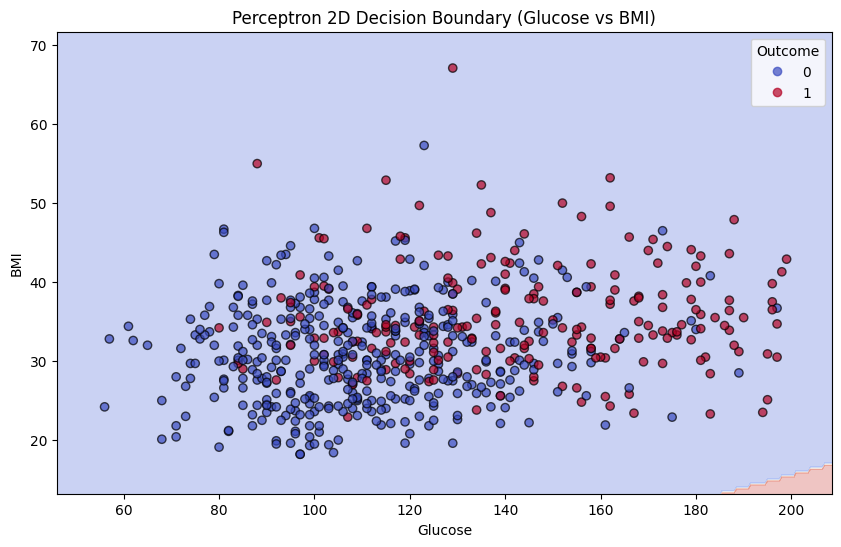

In [57]:
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
scatter = plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train_arr, cmap='coolwarm', edgecolors='k', alpha=0.7)
plt.legend(*scatter.legend_elements(), title="Outcome")
plt.title('Perceptron 2D Decision Boundary (Glucose vs BMI)')
plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.show()

## Lab Task 4: Gaussian Weight Initialization

In [62]:
class PerceptronGaussianInit(PerceptronWithTracking):
    def fit(self, X, y):
        n_samples, n_features = X.shape

        # 1. Initialize weights using a Gaussian (Normal) distribution
        # mean = 0, standard deviation = 0.01
        np.random.seed(42)
        self.weights = np.random.normal(loc=0.0, scale=0.01, size=n_features)
        self.bias = 0.0
        self.errors_log = []

        # 2. Train the perceptron
        for epoch in range(self.epochs):
            errors = 0
            for idx, x_i in enumerate(X):
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_predicted = 1 if linear_output >= 0 else 0

                update = self.lr * (y[idx] - y_predicted)
                if update != 0:
                    self.weights += update * x_i
                    self.bias += update
                    errors += 1
            self.errors_log.append(errors)

In [65]:
gaussian_model = PerceptronGaussianInit(learning_rate=0.01, epochs=100)
gaussian_model.fit(X_train_arr, y_train_arr)

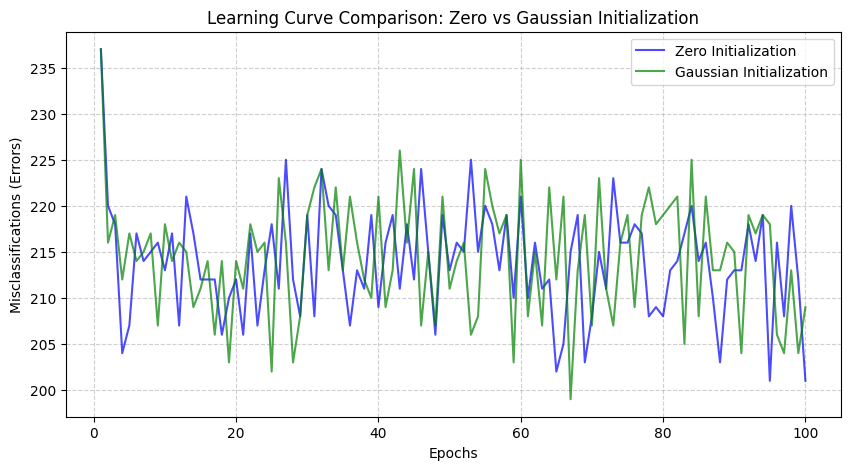

In [66]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(model.errors_log) + 1), model.errors_log, label='Zero Initialization', color='blue', alpha=0.7)
plt.plot(range(1, len(gaussian_model.errors_log) + 1), gaussian_model.errors_log, label='Gaussian Initialization', color='green', alpha=0.7)
plt.title('Learning Curve Comparison: Zero vs Gaussian Initialization')
plt.xlabel('Epochs')
plt.ylabel('Misclassifications (Errors)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [67]:
# Compare final learned weights
print("Features:", list(X_train.columns))
print(f"Zero-Init Final Weights:     {model.weights}")
print(f"Gaussian-Init Final Weights: {gaussian_model.weights}")

Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Zero-Init Final Weights:     [  7.61     -0.8     -10.105     1.11      1.72      3.095     2.41506
  -2.09   ]
Gaussian-Init Final Weights: [  7.97496714  -1.91138264 -11.15352311   1.4752303    3.40765847
   1.70365863   2.15011213  -1.82232565]


## Lab Task 5: Xavier/Glorot Initialization

In [70]:
class PerceptronXavierInit(PerceptronWithTracking):
    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Xavier/Glorot Initialization
        # Standard deviation limit: sqrt(2 / (inputs + outputs))
        # Since we have 1 output node, limit = sqrt(2 / (n_features + 1))
        limit = np.sqrt(2.0 / (n_features + 1))

        np.random.seed(42)
        self.weights = np.random.uniform(low=-limit, high=limit, size=n_features)
        self.bias = 0.0
        self.errors_log = []

        # Train the perceptron
        for epoch in range(self.epochs):
            errors = 0
            for idx, x_i in enumerate(X):
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_predicted = 1 if linear_output >= 0 else 0

                update = self.lr * (y[idx] - y_predicted)
                if update != 0:
                    self.weights += update * x_i
                    self.bias += update
                    errors += 1
            self.errors_log.append(errors)

In [72]:
xavier_model = PerceptronXavierInit(learning_rate=0.01, epochs=100)
xavier_model.fit(X_train_arr, y_train_arr)

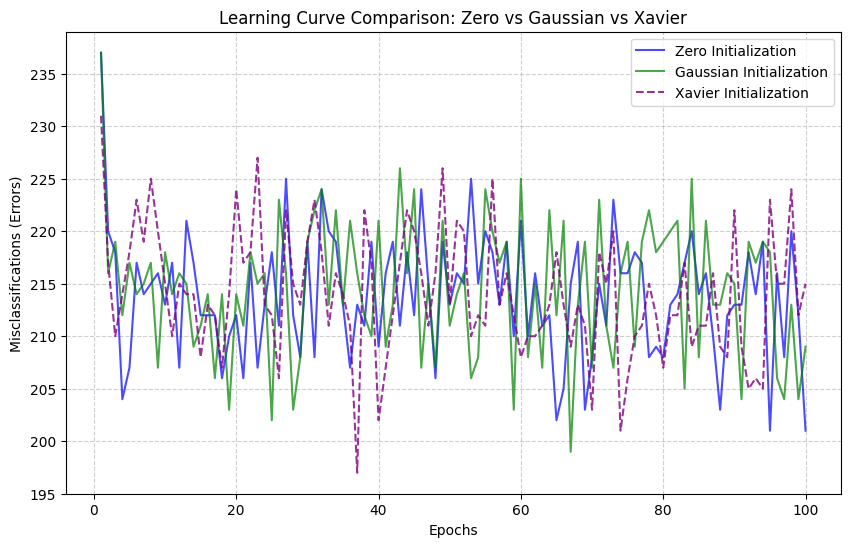

In [73]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(model.errors_log) + 1), model.errors_log, label='Zero Initialization', color='blue', alpha=0.7)
plt.plot(range(1, len(gaussian_model.errors_log) + 1), gaussian_model.errors_log, label='Gaussian Initialization', color='green', alpha=0.7)
plt.plot(range(1, len(xavier_model.errors_log) + 1), xavier_model.errors_log, label='Xavier Initialization', color='purple', alpha=0.8, linestyle='--')
plt.title('Learning Curve Comparison: Zero vs Gaussian vs Xavier')
plt.xlabel('Epochs')
plt.ylabel('Misclassifications (Errors)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Lab Task 6: He/Kaiming Initialization

In [78]:
class PerceptronHeInit(PerceptronWithTracking):
    def fit(self, X, y):
        n_samples, n_features = X.shape

        # He/Kaiming Initialization: standard deviation = sqrt(2 / fan_in)
        std = np.sqrt(2.0 / n_features)

        np.random.seed(42)
        self.weights = np.random.normal(loc=0.0, scale=std, size=n_features)
        self.bias = 0.0
        self.errors_log = []

        for epoch in range(self.epochs):
            errors = 0
            for idx, x_i in enumerate(X):
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_predicted = 1 if linear_output >= 0 else 0

                update = self.lr * (y[idx] - y_predicted)
                if update != 0:
                    self.weights += update * x_i
                    self.bias += update
                    errors += 1
            self.errors_log.append(errors)

In [80]:
he_model = PerceptronHeInit(learning_rate=0.01, epochs=100)
he_model.fit(X_train_arr, y_train_arr)
he_preds = he_model.predict(X_test_arr)
he_accuracy = np.mean(he_preds == y_test_arr) * 100

In [81]:
print(f"He-Init Final Weights: {he_model.weights}")
print(f"He-Init Test Accuracy: {he_accuracy:.2f}%")

He-Init Final Weights: [  7.74835708  -1.21913215 -10.45115573   1.59151493   1.96792331
   3.00893152   3.18464641  -1.65628264]
He-Init Test Accuracy: 62.99%


## Lab Task 7: Orthogonal Initialization

In [82]:
class PerceptronOrthogonalInit(PerceptronWithTracking):
    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Orthogonal Initialization
        # We generate a random matrix of shape (n_features, n_features)
        # and compute its QR decomposition.
        np.random.seed(42)
        random_matrix = np.random.normal(0.0, 1.0, (n_features, n_features))
        q, r = np.linalg.qr(random_matrix)

        # Take the first column for a single-layer perceptron weight vector
        self.weights = q[:, 0]
        self.bias = 0.0
        self.errors_log = []

        for epoch in range(self.epochs):
            errors = 0
            for idx, x_i in enumerate(X):
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_predicted = 1 if linear_output >= 0 else 0

                update = self.lr * (y[idx] - y_predicted)
                if update != 0:
                    self.weights += update * x_i
                    self.bias += update
                    errors += 1
            self.errors_log.append(errors)

In [83]:
ortho_model = PerceptronOrthogonalInit(learning_rate=0.01, epochs=100)
ortho_model.fit(X_train_arr, y_train_arr)
ortho_preds = ortho_model.predict(X_test_arr)
ortho_accuracy = np.mean(ortho_preds == y_test_arr) * 100

In [84]:
print(f"Orthogonal-Init Final Weights: {ortho_model.weights}")
print(f"Orthogonal-Init Test Accuracy: {ortho_accuracy:.2f}%")

Orthogonal-Init Final Weights: [  7.79045193  -0.54578232 -10.96498405   0.75637569   1.80259617
   3.00039495   2.15726346  -1.12769286]
Orthogonal-Init Test Accuracy: 62.99%


## Lab Task 8: Comparative Analysis of Weight Initialization Techniques

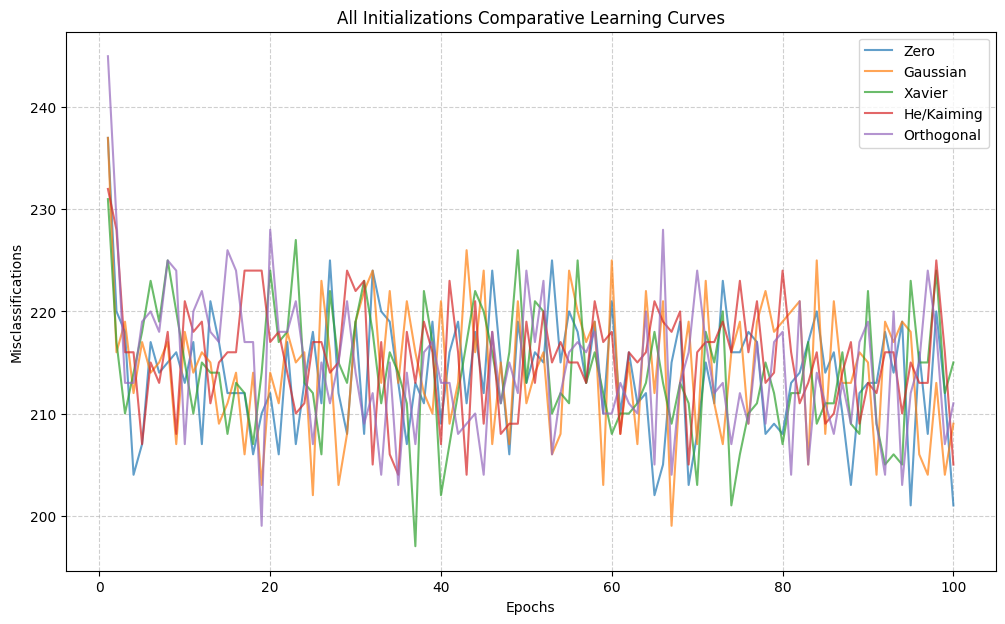

Method          | Final Epoch Errors   | Test Accuracy  
----------------------------------------------------------
Zero            | 201                  | 62.99%
Gaussian        | 209                  | 61.69%
Xavier          | 215                  | 63.64%
He/Kaiming      | 205                  | 62.99%
Orthogonal      | 211                  | 62.99%


In [76]:
plt.figure(figsize=(12, 7))
plt.plot(range(1, 101), model.errors_log, label='Zero', alpha=0.7)
plt.plot(range(1, 101), gaussian_model.errors_log, label='Gaussian', alpha=0.7)
plt.plot(range(1, 101), xavier_model.errors_log, label='Xavier', alpha=0.7)
plt.plot(range(1, 101), he_model.errors_log, label='He/Kaiming', alpha=0.7)
plt.plot(range(1, 101), ortho_model.errors_log, label='Orthogonal', alpha=0.7)

plt.title('All Initializations Comparative Learning Curves')
plt.xlabel('Epochs')
plt.ylabel('Misclassifications')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Print metrics comparison table
print(f"{'Method':<15} | {'Final Epoch Errors':<20} | {'Test Accuracy':<15}")
print("-" * 58)
print(f"{'Zero':<15} | {model.errors_log[-1]:<20} | {accuracy:.2f}%")
print(f"{'Gaussian':<15} | {gaussian_model.errors_log[-1]:<20} | {np.mean(gaussian_model.predict(X_test_arr) == y_test_arr)*100:.2f}%")
print(f"{'Xavier':<15} | {xavier_model.errors_log[-1]:<20} | {np.mean(xavier_model.predict(X_test_arr) == y_test_arr)*100:.2f}%")
print(f"{'He/Kaiming':<15} | {he_model.errors_log[-1]:<20} | {he_accuracy:.2f}%")
print(f"{'Orthogonal':<15} | {ortho_model.errors_log[-1]:<20} | {ortho_accuracy:.2f}%")

## Lab Task 9: Experimental Study and Interpretation

In [85]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

In [86]:
cancer = load_breast_cancer()
X_cancer, y_cancer = cancer.data, cancer.target

In [87]:
scaler = StandardScaler()
X_cancer_scaled = scaler.fit_transform(X_cancer)

In [90]:
# Helper to dynamically update class weights dynamically based on seed
def run_experiment(initialization_type, seed, epochs=50):
    np.random.seed(seed)
    n_features = X_cancer_scaled.shape[1]

    if initialization_type == 'Zero':
        weights = np.zeros(n_features)
    elif initialization_type == 'Gaussian':
        weights = np.random.normal(loc=0.0, scale=0.01, size=n_features)
    elif initialization_type == 'Xavier':
        limit = np.sqrt(2.0 / (n_features + 1))
        weights = np.random.uniform(low=-limit, high=limit, size=n_features)
    elif initialization_type == 'He':
        std = np.sqrt(2.0 / n_features)
        weights = np.random.normal(loc=0.0, scale=std, size=n_features)
    elif initialization_type == 'Orthogonal':
        random_matrix = np.random.normal(0.0, 1.0, (n_features, n_features))
        q, _ = np.linalg.qr(random_matrix)
        weights = q[:, 0]

    bias = 0.0
    errors_log = []
    for epoch in range(epochs):
        errors = 0
        for idx, x_i in enumerate(X_cancer_scaled):
            linear_output = np.dot(x_i, weights) + bias
            y_predicted = 1 if linear_output >= 0 else 0
            update = 0.01 * (y_cancer[idx] - y_predicted)
            if update != 0:
                weights += update * x_i
                bias += update
                errors += 1
        errors_log.append(errors)
        if errors == 0:
            return epoch + 1, weights
    return epochs, weights

In [91]:
seeds = [12, 42, 100, 2023, 9999]
results = {init: [] for init in ['Zero', 'Gaussian', 'Xavier', 'He', 'Orthogonal']}

for init in results.keys():
    for s in seeds:
        conv_epoch, _ = run_experiment(init, s)
        results[init].append(conv_epoch)

In [92]:
print(f"{'Method':<15} | {'Average Convergence Epochs (5 Runs)':<35}")
print("-" * 55)
for init, epochs_list in results.items():
    avg_epoch = np.mean(epochs_list)
    print(f"{init:<15} | {avg_epoch:<35}")

Method          | Average Convergence Epochs (5 Runs)
-------------------------------------------------------
Zero            | 50.0                               
Gaussian        | 50.0                               
Xavier          | 50.0                               
He              | 50.0                               
Orthogonal      | 50.0                               
